# Expected evidence: where the Bayes factor comes from

The noiseless counterpart of the nested-sampling retrievals. The point-source model fitted to a noiseless hyperillumination truth leaves a residual that it cannot absorb. In whitened units (every bin divided by its $\sigma_{\rm bin}$, each detector's baseline removed) this is
$$r_\perp = \frac{h - m_{\rm ps}(\hat A_B) - \hat c}{\sigma_{\rm bin}}, \qquad \lVert r_\perp\rVert^2 = \chi^2_{\min},$$
the $\chi^2$ that `fit_naive` returns. The extended-source and the point-source model have the same parameters and priors, so their Occam factors nearly cancel and the Bayes factor follows the likelihood ratio. Linearised around the truth, for data $d = h + \sigma z$,
$$\ln B({\rm ext\ vs\ ps}) \approx \tfrac12\chi^2_{\min} + \zeta\sqrt{\chi^2_{\min}}, \qquad \zeta = \hat r_\perp\cdot z \sim N(0, 1).$$
So $\langle\ln B\rangle = \chi^2_{\min}/2$ with a scatter of $\sqrt{\chi^2_{\min}}$ over noise realisations, and both follow from one noiseless fit.

1. **Per-bin evidence** - $r_\perp^2$ per phase bin sums to $2\langle\ln B\rangle$, so it shows at which orbital phases the expected evidence arises (the deterministic counterpart of `plot_dynesty.ipynb` §3, which shows one noisy run).
2. **$\langle\ln B\rangle$ table** - every paper planet in every retrieval mode, both point-source fits.
3. **Detection probabilities** - $P(\ln B > x)$ over noise realisations, also for other numbers of orbits ($\chi^2_{\min} \propto n_{\rm orbits}$).
4. **The bias–evidence plane** - $(\Delta A_B/\sigma_{A_B})^2$ against $\chi^2_{\min}/2$ for every planet, mode and fit: whether the bias or the evidence becomes significant first.

This holds only for equal parameter counts. Against the point-source fit with redistribution the prior of $F$ adds an Occam term of about 3 nats (for $F \sim U(0, 0.5)$) and the posterior of $F$ is one-sided, so $\chi^2/2$ of that fit is listed as the likelihood part only and gets no probabilities. The test of the prediction against the stored retrievals is in `Dynesty Fits/dynesty_series.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import contextlib, io
import matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import display
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
from simple_bias_analysis import *
from HItargets_utils import *
from paper_plot_utils import paper_figure, paper_theme

set_plot_style()

In [2]:
# Baseline settings (HItargets_utils.py)
A_B_true = DEFAULT_A_B                    # injected Bond albedo of the hyperillumination truth
A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B
u, u_B = DEFAULT_U, DEFAULT_U_B
n_orbits, n_bins = DEFAULT_N_ORBITS, DEFAULT_N_BINS
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)

# The retrieval modes: every band singly plus the joint NIRSpec fit (a tuple = one joint fit: shared A_B / F, a baseline per detector)
LRS, JOINT = "MIRI/LRS", tuple(JWST_BANDS[:2])
PRIMARY = {"joint NIRSpec": JOINT, "MIRI/LRS": LRS}          # the paper's primary modes, by label, in wavelength order
reference_planets = ("TOI-2431 b", "K2-141 b")               # the planets of the per-bin figures and of the detection probabilities

# Template cfg: the band, the planet and the noise are replaced per fit (retrieval_cfg / instrument_retrievals); sigma_1min = 100 only serves rows without a noise level
l1, l2 = filter_lambda(LRS)
cfg = FittingConfig(planet=hi_planets_by_name(reference_planets[0]), filter_path=filter_loc(LRS), l1=l1, l2=l2, A_=A_model,
                    sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_B=u_B, u=u)

## 1. Per-bin evidence

For each reference planet, the noiseless $A_B$-only fit in the two primary modes; one column per detector (the two NIRSpec arrays come from one joint fit and share $\hat A_B$). Top: the residual, truth minus fitted point-source model with the baseline removed, unbinned and per bin, against $\pm\sigma_{\rm bin}$. Bottom: $r_\perp^2$ per bin. The bars of one fit sum to $\chi^2_{\min} = 2\langle\ln B\rangle$. Grey: transit window, light orange: occultation window, hatched: within 0.1 in phase of a quadrature.

What to look for: the residual has the shape $-\cos 4\pi\phi$ (extra flux at the quadratures, where the penumbral ring is seen face-on), plus a flat in-occultation level, where both models are zero and only the fitted baseline remains. The budget tables under each figure give the share of $\chi^2_{\min}$ per window: how much of the expected evidence rests on the occultation level against the quadratures, and how little on the transit. A bin counts to an eclipse window if the eclipse overlaps it.

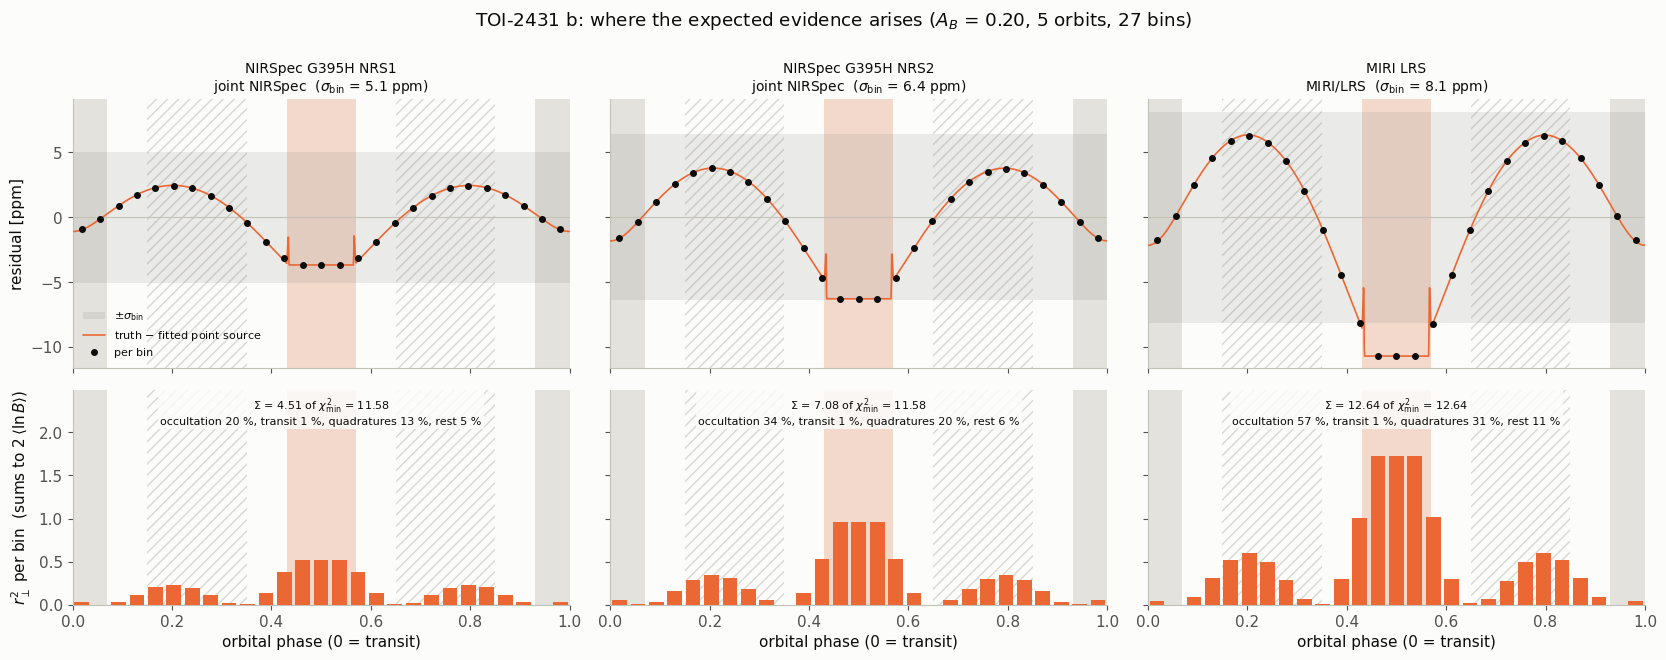

TOI-2431 b, joint NIRSpec: A_B,fit = 0.1575 (bias -0.0425),  chi2_min = 11.584  ->  <ln B> = 5.79 +- 3.40
          detector  chi2  occultation  transit  quadratures  rest  occultation [%]  transit [%]  quadratures [%]  rest [%]  share [%]
NIRSpec G395H NRS1  4.51         2.34   0.0664         1.52 0.583             20.2        0.573             13.1      5.03       38.9
NIRSpec G395H NRS2  7.08         3.94    0.124         2.34 0.664               34         1.07             20.2      5.74       61.1
               all  11.6         6.28    0.191         3.86  1.25             54.3         1.65             33.3      10.8        100 

TOI-2431 b, MIRI/LRS: A_B,fit = 0.1402 (bias -0.0598),  chi2_min = 12.635  ->  <ln B> = 6.32 +- 3.55
detector  chi2  occultation  transit  quadratures  rest  occultation [%]  transit [%]  quadratures [%]  rest [%]  share [%]
MIRI LRS  12.6         7.18   0.0945         3.92  1.44             56.9        0.748               31      11.4        100 



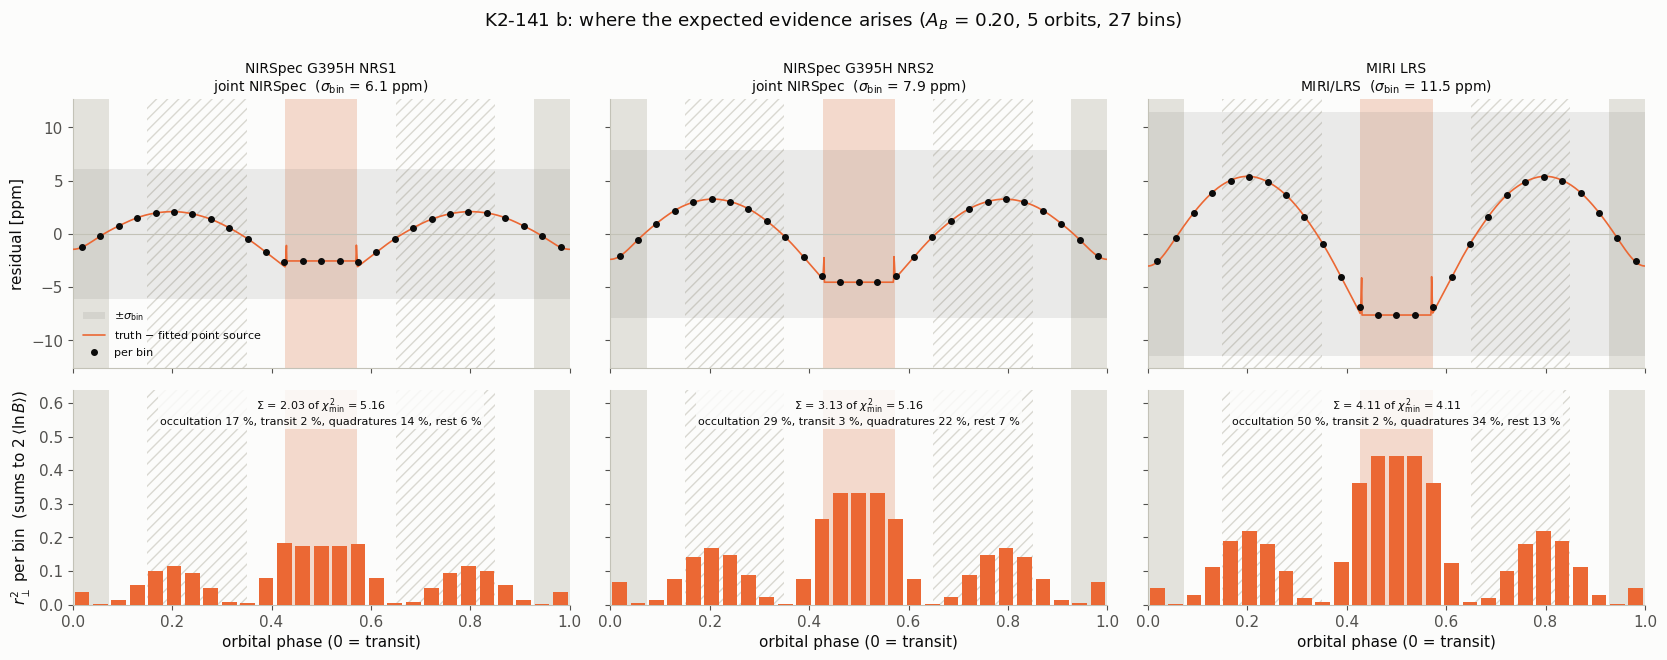

K2-141 b, joint NIRSpec: A_B,fit = 0.1576 (bias -0.0424),  chi2_min = 5.157  ->  <ln B> = 2.58 +- 2.27
          detector  chi2  occultation  transit  quadratures  rest  occultation [%]  transit [%]  quadratures [%]  rest [%]  share [%]
NIRSpec G395H NRS1  2.03        0.886   0.0808        0.738 0.322             17.2         1.57             14.3      6.24       39.3
NIRSpec G395H NRS2  3.13         1.51    0.145         1.14 0.339             29.3         2.81             22.1      6.57       60.7
               all  5.16          2.4    0.226         1.88  0.66             46.4         4.37             36.4      12.8        100 

K2-141 b, MIRI/LRS: A_B,fit = 0.1363 (bias -0.0637),  chi2_min = 4.114  ->  <ln B> = 2.06 +- 2.03
detector  chi2  occultation  transit  quadratures  rest  occultation [%]  transit [%]  quadratures [%]  rest [%]  share [%]
MIRI LRS  4.11         2.05      0.1         1.41 0.551             49.8         2.43             34.4      13.4        100 



In [3]:
PAPER_MODE = False
EV = {}   # {planet: {mode label: evidence_residual}}
for name in reference_planets:
    pl = hi_planets_by_name(name)
    cases = {label: retrieval_cfg(cfg, pl, ins) for label, ins in PRIMARY.items()}
    fig, axes, EV[name] = plot_evidence_bins(cases, A_B_true, **kw)
    paper_figure(f"evidence_bins_{name.replace(' ', '')}", PAPER_MODE, fig=fig)
    plt.show()
    for label, c in cases.items():
        ev = EV[name][label]
        print(f"{name}, {label}: A_B,fit = {ev['A_B_fit']:.4f} (bias {ev['A_B_fit'] - A_B_true:+.4f}),  chi2_min = {ev['chi2']:.3f}  ->  <ln B> = {ev['chi2'] / 2:.2f} +- {np.sqrt(ev['chi2']):.2f}")
        print(evidence_budget(ev, c, labels=[instrument_label(d, oneline=True) for d in detectors(PRIMARY[label])]).to_string(index=False, float_format=lambda v: f"{v:.3g}"), "\n")

**Consistency of the decomposition.** The mismatch at the true parameters splits into the part the fit absorbs and the part it leaves, $\lVert r\rVert^2/\sigma^2 = (\Delta A_B/\sigma_{A_B})^2 + \chi^2_{\min}$, exactly for a linear model and to first order here. The cell prints both sides, with the Fisher $\sigma_{A_B}$ at the fit. The second term is the evidence, the first the bias: their ratio says whether the evidence or the bias becomes significant first as observing time is added.

In [4]:
for name in reference_planets:
    pl = hi_planets_by_name(name)
    for label, ins in PRIMARY.items():
        c = retrieval_cfg(cfg, pl, ins)
        fit = fit_truth(c, A_B_true, fisher=True, **kw)["naive"]
        truth = [model_pcurve(d, "hyperillum", A_B_true, **kw)[1] for d in c] if is_detector_set(c) else model_pcurve(c, "hyperillum", A_B_true, **kw)[1]
        r2 = fit_chi2(c, truth, "naive", A_B_true, **kw)   # |r|^2 / sigma^2 at the true A_B, baseline(s) removed
        b2 = (fit["bias_A_B"] / fit["sigma_A_B"]) ** 2
        print(f"{name:11s} {label:14s} |r|^2 = {r2:6.2f}   (dA_B/sigma)^2 + chi2_min = {b2:5.2f} + {fit['chi2']:6.2f} = {b2 + fit['chi2']:6.2f}   ->  {100 * fit['chi2'] / r2:.0f} % of the mismatch stays in the residual")

TOI-2431 b  joint NIRSpec  |r|^2 =  14.22   (dA_B/sigma)^2 + chi2_min =  2.56 +  11.58 =  14.14   ->  81 % of the mismatch stays in the residual
TOI-2431 b  MIRI/LRS       |r|^2 =  13.97   (dA_B/sigma)^2 + chi2_min =  1.27 +  12.64 =  13.90   ->  90 % of the mismatch stays in the residual
K2-141 b    joint NIRSpec  |r|^2 =   6.50   (dA_B/sigma)^2 + chi2_min =  1.30 +   5.16 =   6.45   ->  79 % of the mismatch stays in the residual
K2-141 b    MIRI/LRS       |r|^2 =   4.70   (dA_B/sigma)^2 + chi2_min =  0.56 +   4.11 =   4.67   ->  87 % of the mismatch stays in the residual


## 2. $\langle\ln B\rangle$ for every planet and mode

`evidence_table`: each planet of `PAPER_PLANETS` at its own geometry and its own noise in every mode of `JWST_RETRIEVALS`, fitted with the point-source model without (`naive`) and with redistribution (`naive_redist`). One tidy row per planet, mode and fit.

- `naive`: `lnB_mean` $= \chi^2_{\min}/2$, `lnB_sd` $= \sqrt{\chi^2_{\min}}$ and $P(\ln B > x)$ for the notebook's `n_orbits`.
- `naive_redist`: `half_chi2` is only the **likelihood part** of $\ln B$(ext vs ps+$F$), without the Occam term of the $F$ prior, so it has no `lnB` columns; `z_F` $= \sqrt{\Delta\chi^2_F}$ is the significance of the spurious $F$.
- Rows without a noise level (MIRI imaging for most planets) keep their fitted values; everything that needs the noise is NaN.

What to look for: $\langle\ln B\rangle$ against the thresholds 2.5 and 5 (moderate and strong evidence on the scale of Trotta 2008), which planets and modes reach them, and that `lnB_sd` is comparable to `lnB_mean` wherever the evidence is weak, so a single realisation there says little.

In [5]:
tab = evidence_table(cfg, PAPER_PLANETS, JWST_RETRIEVALS, A_B_true, **kw)
tab["mode"] = tab["instrument"].map(lambda ins: instrument_label(ins, oneline=True))
fmt = lambda v: f"{v:.3g}"
pivot = lambda col, fit: tab[tab.fit == fit].pivot(index="planet", columns="mode", values=col).reindex(index=list(PAPER_PLANETS), columns=list(dict.fromkeys(tab["mode"])))

print(f"<ln B> = chi2_min / 2, A_B-only fit ({n_orbits} orbits, A_B = {A_B_true:g})")
display(pivot("lnB_mean", "naive").style.format(fmt, na_rep="-"))
print("scatter of ln B over noise realisations, sqrt(chi2_min)")
display(pivot("lnB_sd", "naive").style.format(fmt, na_rep="-"))
print("chi2 / 2 of the fit with redistribution: the likelihood part of ln B(ext vs ps+F) only, no Occam term")
display(pivot("half_chi2", "naive_redist").style.format(fmt, na_rep="-"))

TOI-2260 b: no noise level on MIRI/F1280W, MIRI/F1500W, MIRI/F1800W (no PandExo mode, no CUSTOM_SIGMA_1MIN entry): fitted without one (the fitted A_B does not depend on it), so no Fisher sigma
K2-141 b: no noise level on MIRI/F1280W, MIRI/F1500W, MIRI/F1800W (no PandExo mode, no CUSTOM_SIGMA_1MIN entry): fitted without one (the fitted A_B does not depend on it), so no Fisher sigma
K2-131 b: no noise level on MIRI/F1280W, MIRI/F1500W, MIRI/F1800W (no PandExo mode, no CUSTOM_SIGMA_1MIN entry): fitted without one (the fitted A_B does not depend on it), so no Fisher sigma
TOI-561 b: no noise level on MIRI/F1280W, MIRI/F1500W, MIRI/F1800W (no PandExo mode, no CUSTOM_SIGMA_1MIN entry): fitted without one (the fitted A_B does not depend on it), so no Fisher sigma
Kepler-78 b: no noise level on MIRI/F1280W, MIRI/F1500W, MIRI/F1800W (no PandExo mode, no CUSTOM_SIGMA_1MIN entry): fitted without one (the fitted A_B does not depend on it), so no Fisher sigma
TOI-1444 b: no noise level on MIRI/F128

mode,NIRSpec G395H NRS1,NIRSpec G395H NRS2,NIRSpec G395H NRS1 + NRS2,MIRI LRS,MIRI F1280W,MIRI F1500W,MIRI F1800W
planet,,,,,,,
TOI-2431 b,2.25,3.53,5.79,6.32,0.888,0.9,0.458
TOI-2260 b,0.781,1.02,1.81,0.983,-,-,-
K2-141 b,1.01,1.56,2.58,2.06,-,-,-
K2-131 b,0.177,0.28,0.459,0.186,-,-,-
TOI-561 b,0.325,0.482,0.81,0.604,-,-,-
Kepler-78 b,0.0575,0.0917,0.149,0.0793,-,-,-
TOI-1444 b,0.133,0.201,0.334,0.199,-,-,-
TOI-1798.02,0.0946,0.16,0.255,0.17,-,-,-
HD 80653 b,0.22,0.319,0.539,0.431,-,-,-


scatter of ln B over noise realisations, sqrt(chi2_min)


mode,NIRSpec G395H NRS1,NIRSpec G395H NRS2,NIRSpec G395H NRS1 + NRS2,MIRI LRS,MIRI F1280W,MIRI F1500W,MIRI F1800W
planet,,,,,,,
TOI-2431 b,2.12,2.66,3.4,3.55,1.33,1.34,0.958
TOI-2260 b,1.25,1.43,1.9,1.4,-,-,-
K2-141 b,1.42,1.77,2.27,2.03,-,-,-
K2-131 b,0.595,0.748,0.958,0.611,-,-,-
TOI-561 b,0.807,0.982,1.27,1.1,-,-,-
Kepler-78 b,0.339,0.428,0.547,0.398,-,-,-
TOI-1444 b,0.516,0.633,0.818,0.631,-,-,-
TOI-1798.02,0.435,0.566,0.715,0.584,-,-,-
HD 80653 b,0.663,0.799,1.04,0.928,-,-,-


chi2 / 2 of the fit with redistribution: the likelihood part of ln B(ext vs ps+F) only, no Occam term


mode,NIRSpec G395H NRS1,NIRSpec G395H NRS2,NIRSpec G395H NRS1 + NRS2,MIRI LRS,MIRI F1280W,MIRI F1500W,MIRI F1800W
planet,,,,,,,
TOI-2431 b,0.858,1.36,2.73,2.31,0.302,0.301,0.15
TOI-2260 b,0.341,0.442,0.921,0.406,-,-,-
K2-141 b,0.483,0.748,1.46,0.937,-,-,-
K2-131 b,0.0977,0.158,0.299,0.103,-,-,-
TOI-561 b,0.185,0.277,0.535,0.337,-,-,-
Kepler-78 b,0.0299,0.0495,0.097,0.0425,-,-,-
TOI-1444 b,0.0755,0.116,0.221,0.112,-,-,-
TOI-1798.02,0.0545,0.0962,0.177,0.102,-,-,-
HD 80653 b,0.128,0.19,0.372,0.253,-,-,-


In [6]:
# The primary modes in full: both fits per planet (the rows of tab:res_planets)
primary = tab[tab["instrument"].isin([instrument_key(ins) for ins in PRIMARY.values()])]
cols = ["planet", "mode", "fit", "A_B_fit", "bias_A_B", "sigma_A_B", "bias_sigma", "F_fit", "z_F", "chi2", "half_chi2", "lnB_mean", "lnB_sd"] + [c for c in tab.columns if c.startswith("P_lnB")]
print(primary[cols].to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.3g}"))

     planet                      mode          fit  A_B_fit  bias_A_B  sigma_A_B  bias_sigma   F_fit   z_F  chi2  half_chi2  lnB_mean  lnB_sd  P_lnB_gt_2.5  P_lnB_gt_5
 TOI-2431 b NIRSpec G395H NRS1 + NRS2        naive    0.158   -0.0425     0.0266         1.6       -     -  11.6       5.79      5.79     3.4         0.833       0.592
 TOI-2431 b                  MIRI LRS        naive     0.14   -0.0598     0.0531        1.13       -     -  12.6       6.32      6.32    3.55         0.859       0.645
 TOI-2431 b NIRSpec G395H NRS1 + NRS2 naive_redist    0.106   -0.0943     0.0346        2.72   0.014  2.47  5.47       2.73         -       -             -           -
 TOI-2431 b                  MIRI LRS naive_redist   0.0309    -0.169     0.0705         2.4 0.00581  2.83  4.62       2.31         -       -             -           -
 TOI-2260 b NIRSpec G395H NRS1 + NRS2        naive    0.172   -0.0279     0.0541       0.516       -     -  3.61       1.81      1.81     1.9         0.357     

## 3. Detection probabilities

In the linear prediction $\ln B \sim N(\chi^2_{\min}/2,\ \chi^2_{\min})$ over noise realisations, so $P(\ln B > x) = 1 - \Phi\!\left[(x - \chi^2_{\min}/2)/\sqrt{\chi^2_{\min}}\right]$ (`evidence_probability`). $\chi^2_{\min} \propto n_{\rm orbits}/\sigma_{1\rm min}^2$, so another number of orbits needs no refit: `N_ORBITS_ALT` lists the alternatives printed next to the notebook's `n_orbits` (2 orbits is roughly one JWST GO 8864 visit of TOI-2431 b). The figure shows the same probabilities as a function of the number of orbits for the reference planets.

What to look for: how many orbits each planet and mode needs before strong evidence ($\ln B > 5$) is more likely than not, and how much of the probability at few orbits is the scatter $\sqrt{\chi^2_{\min}}$ rather than the mean.

    planet                      mode  n_orbits  t_obs_h  lnB_mean  lnB_sd  P(ln B > 2.5)  P(ln B > 5)
TOI-2431 b NIRSpec G395H NRS1 + NRS2         5     26.9      5.79     3.4          0.833        0.592
TOI-2431 b NIRSpec G395H NRS1 + NRS2         2     10.8      2.32    2.15          0.466        0.106
TOI-2431 b                  MIRI LRS         5     26.9      6.32    3.55          0.859        0.645
TOI-2431 b                  MIRI LRS         2     10.8      2.53    2.25          0.505        0.136
  K2-141 b NIRSpec G395H NRS1 + NRS2         5     33.6      2.58    2.27          0.514        0.143
  K2-141 b NIRSpec G395H NRS1 + NRS2         2     13.5      1.03    1.44          0.153      0.00286
  K2-141 b                  MIRI LRS         5     33.6      2.06    2.03          0.414       0.0734
  K2-141 b                  MIRI LRS         2     13.5     0.823    1.28         0.0955     0.000565


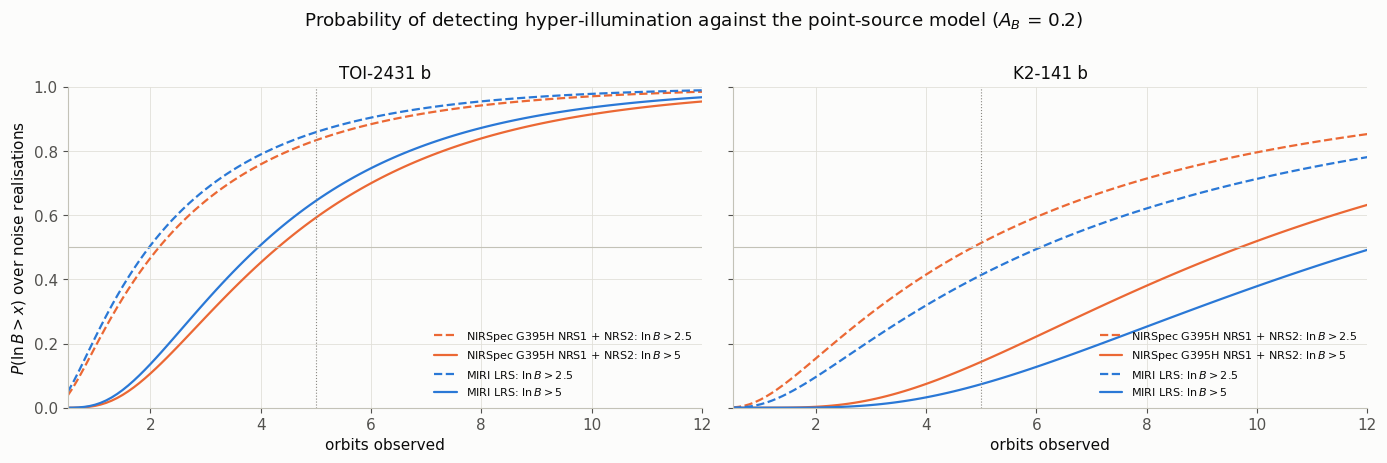

In [7]:
PAPER_MODE = False
N_ORBITS_ALT = (2,)                       # other numbers of orbits, next to n_orbits
THRESHOLDS = tab.attrs["thresholds"]      # ln B thresholds of the table (2.5, 5)

ref = tab[(tab.fit == "naive") & tab["planet"].isin(reference_planets) & tab["instrument"].isin([instrument_key(ins) for ins in PRIMARY.values()])]
rows = []
for _, r in ref.iterrows():
    for n in (n_orbits, *N_ORBITS_ALT):
        s = n / n_orbits
        rows.append(dict(planet=r["planet"], mode=r["mode"], n_orbits=n, t_obs_h=n * 24. * hi_planets_by_name(r["planet"]).period, lnB_mean=0.5 * s * r["chi2"], lnB_sd=np.sqrt(s * r["chi2"]),
                         **{f"P(ln B > {x:g})": float(evidence_probability(r["chi2"], x, s)) for x in THRESHOLDS}))
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

n_grid = np.linspace(0.5, 12., 116)
fig, axs = plt.subplots(1, len(reference_planets), figsize=(7. * len(reference_planets), 4.6), sharey=True, squeeze=False)
for ax, name in zip(axs.ravel(), reference_planets):
    for (_, r), col in zip(ref[ref.planet == name].iterrows(), (C_HI, C_REDIST)):
        for x, ls in zip(THRESHOLDS, ("--", "-")):
            ax.plot(n_grid, evidence_probability(r["chi2"], x, n_grid / n_orbits), color=col, ls=ls, lw=1.6, label=rf"{r['mode']}: $\ln B > {x:g}$")
    ax.axhline(0.5, color=AXIS, lw=.8)
    ax.axvline(n_orbits, color=MUTED, lw=.8, ls=":")
    ax.set_xlabel("orbits observed"); ax.set_title(name); ax.set_ylim(0., 1.); ax.set_xlim(n_grid[0], n_grid[-1])
    ax.legend(fontsize=8, loc="lower right")
axs[0, 0].set_ylabel(r"$P(\ln B > x)$ over noise realisations")
fig.suptitle(rf"Probability of detecting hyper-illumination against the point-source model ($A_B$ = {A_B_true:g})", y=1.0)
fig.tight_layout()
paper_figure("evidence_probability_vs_orbits", PAPER_MODE, fig=fig)
plt.show()

## 4. The bias–evidence plane

Every planet and mode of the table of section 2 in one plane: the significance of the albedo bias, $(\Delta A_B/\sigma_{A_B})^2$, against $\chi^2_{\min}/2$. For the $A_B$-only fit (circles) the abscissa is the expected evidence $\langle\ln B\rangle$ for the extended-source model. For the fit with redistribution (squares) it is only the likelihood part of $\ln B$(ext vs ps+$F$): the Occam term of the $F$ prior, about 3 nats for $F \sim U(0, 0.5)$, comes on top in favour of the extended source, so those points are not a detection forecast. Rows without a noise level are left out.

Both axes are $\propto n_{\rm orbits}/\sigma_{1\rm min}^2$, so more observing time moves a point along a line of slope 1 in this log–log plane, and the ratio of the two, the split of the mismatch into the part the fit absorbs and the part it cannot (section 1), is a property of the planet, the band and the fitted model alone. The dotted line is that track for `MARK_CASE`, with the positions for the numbers of orbits in `N_ORBITS_MARK`. Dashed: $1\sigma$ and $2\sigma$ bias, and $\ln B = 2.5$ and $5$. Solid: the line through the crossing of the $2\sigma$ and the $\ln B = 5$ lines (`PAIR`), $(\Delta A_B/\sigma_{A_B})^2 = 0.8\,\chi^2_{\min}/2$. The tracks run parallel to it, so a point below it reaches $\ln B = 5$ before a $2\sigma$ bias, and a point above it reaches the $2\sigma$ bias first. The line depends on the pair of thresholds: $1\sigma$ with $\ln B = 2.5$ would give $(\Delta A_B/\sigma_{A_B})^2 = 0.4\,\chi^2_{\min}/2$, and points between the two lines change order with that choice.

What to look for: on which side of the solid line the two fits lie. Below it, the evidence becomes strong before the bias reaches $2\sigma$: the data would reveal the wrong model while the albedo is still within twice its error bar. Above it, the albedo is biased by $2\sigma$ before the misfit reaches $\ln B = 5$, the case in which a Bayes factor cannot stand in for the bias (for the fit with redistribution the abscissa is that misfit only, see above). The ratio $(\Delta A_B/\sigma_{A_B})^2/(\chi^2_{\min}/2)$ is constant along a track, so its printed range per fit says how far each fit lies from the line. The printed lists name the planets and modes in the two off-diagonal quadrants of the $1\sigma$ and $\ln B = 2.5$ lines at the notebook's `n_orbits`.

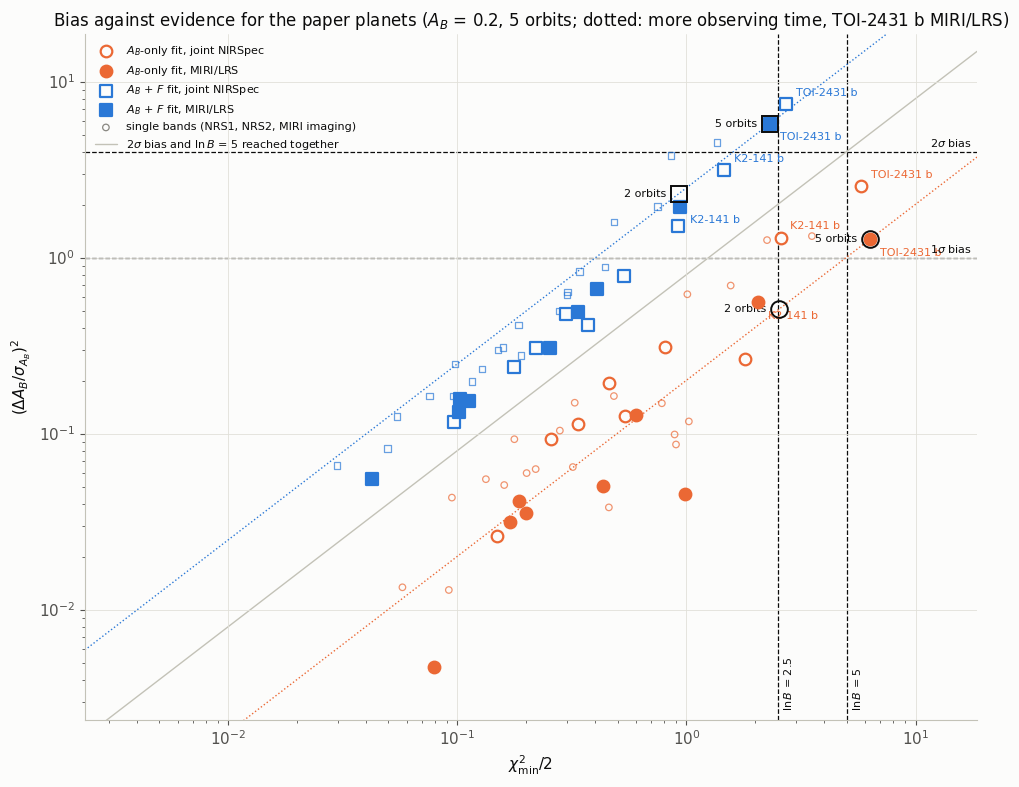

A_B-only fit: 0 of 39 points above the solid line (2 sigma bias before ln B = 5); (dA_B/sigma)^2 / (chi2_min/2) = 0.046 to 0.61
   bias >= 1 sigma but chi2_min / 2 < 2.5: TOI-2431 b [NIRSpec G395H NRS1]
   chi2_min / 2 >= 2.5 but bias < 1 sigma: -
   both: TOI-2431 b [NIRSpec G395H NRS2], TOI-2431 b [NIRSpec G395H NRS1 + NRS2], TOI-2431 b [MIRI LRS], K2-141 b [NIRSpec G395H NRS1 + NRS2]
A_B + F fit (x: likelihood part only): 39 of 39 points above the solid line (2 sigma bias before ln B = 5); (dA_B/sigma)^2 / (chi2_min/2) = 1.1 to 4.4
   bias >= 1 sigma but chi2_min / 2 < 2.5: TOI-2431 b [NIRSpec G395H NRS1], TOI-2431 b [NIRSpec G395H NRS2], TOI-2431 b [MIRI LRS], TOI-2260 b [NIRSpec G395H NRS1 + NRS2], K2-141 b [NIRSpec G395H NRS1], K2-141 b [NIRSpec G395H NRS2], K2-141 b [NIRSpec G395H NRS1 + NRS2], K2-141 b [MIRI LRS]
   chi2_min / 2 >= 2.5 but bias < 1 sigma: -
   both: TOI-2431 b [NIRSpec G395H NRS1 + NRS2]


In [8]:
PAPER_MODE = False
MARK_CASE = ("TOI-2431 b", instrument_key(LRS))   # the planet and mode whose track in observing time is drawn
N_ORBITS_MARK = (n_orbits, 2)                     # positions marked on it
LNB_LINES, SIGMA_LINES = (2.5, 5.), (1., 2.)
PAIR = (SIGMA_LINES[1], LNB_LINES[1])             # the solid line pairs a 2 sigma bias with ln B = 5 and runs through the crossing of those two dashed lines
PAIR_SLOPE = PAIR[0] ** 2 / PAIR[1]               # (dA_B/sigma)^2 = PAIR_SLOPE * chi2_min/2; the tracks in observing time run parallel to it, so below it ln B = 5 comes before a 2 sigma bias

pts = tab[tab["sigma_A_B"].notna() & tab["chi2"].notna()].assign(bias2=lambda t: t["bias_sigma"] ** 2)
MODE_MARK = {instrument_key(JOINT): ("joint NIRSpec", 1.0), instrument_key(LRS): ("MIRI/LRS", 1.0)}   # primary modes: full size; the other bands smaller and paler
FIT_STYLE = {"naive": ("o", C_HI, r"$A_B$-only fit  ($x = \langle\ln B\rangle$)"), "naive_redist": ("s", C_REDIST, r"$A_B$ + $F$ fit  ($x$ = likelihood part of $\ln B$ only)")}

fig, ax = plt.subplots(figsize=(10., 8.))
for fit, (mk, col, lab) in FIT_STYLE.items():
    t = pts[pts.fit == fit]
    prim = t["instrument"].isin(MODE_MARK)
    ax.scatter(t.loc[~prim, "half_chi2"], t.loc[~prim, "bias2"], marker=mk, s=22, facecolor="none", edgecolor=col, linewidths=.9, alpha=.7, zorder=3)
    for ins, fill in ((instrument_key(JOINT), "#fcfcfb"), (instrument_key(LRS), col)):   # legend in wavelength order
        u_ = t[t["instrument"] == ins]
        ax.scatter(u_["half_chi2"], u_["bias2"], marker=mk, s=70, facecolor=fill, edgecolor=col, linewidths=1.6, zorder=4, label=f"{lab.split('  ')[0]}, {MODE_MARK[ins][0]}")
    for _, r in t[prim & t["planet"].isin(reference_planets)].iterrows():
        ax.annotate(r["planet"], (r["half_chi2"], r["bias2"]), xytext=(7, 6) if r["instrument"] == instrument_key(JOINT) else (7, -12), textcoords="offset points", fontsize=8, color=col)   # joint NIRSpec above, MIRI/LRS below its marker
ax.scatter([], [], marker="o", s=22, facecolor="none", edgecolor=MUTED, linewidths=.9, label="single bands (NRS1, NRS2, MIRI imaging)")

for x in LNB_LINES: ax.axvline(x, color=INK, lw=.9, ls="--", zorder=1)
for z in SIGMA_LINES: ax.axhline(z ** 2, color=INK, lw=.9, ls="--", zorder=1)
ax.set_xscale("log"); ax.set_yscale("log")
lo, hi = min(pts["half_chi2"].min(), pts["bias2"].min()) / 2., max(pts["half_chi2"].max(), pts["bias2"].max()) * 2.5
ax.plot([lo, hi], [PAIR_SLOPE * lo, PAIR_SLOPE * hi], color=AXIS, lw=1., zorder=1, label=rf"{PAIR[0]:g}$\sigma$ bias and $\ln B$ = {PAIR[1]:g} reached together")   # (dA_B/sigma)^2 = PAIR_SLOPE * chi2_min / 2
for fit, (mk, col, _) in FIT_STYLE.items():   # the track of MARK_CASE in observing time, both fits
    r = pts[(pts.planet == MARK_CASE[0]) & (pts.instrument == MARK_CASE[1]) & (pts.fit == fit)]
    if not len(r): continue
    x0, y0 = float(r["half_chi2"].iloc[0]), float(r["bias2"].iloc[0])
    ax.plot([lo, hi], [lo * y0 / x0, hi * y0 / x0], color=col, lw=1., ls=":", zorder=2)
    for n in N_ORBITS_MARK:
        ax.plot(x0 * n / n_orbits, y0 * n / n_orbits, marker=mk, ms=12, mfc="none", mec=INK, mew=1.4, zorder=5)
        ax.annotate(f"{n} orbits", (x0 * n / n_orbits, y0 * n / n_orbits), xytext=(-9, 0), textcoords="offset points", fontsize=8, ha="right", va="center")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
for x in LNB_LINES: ax.annotate(rf"$\ln B$ = {x:g}", (x, lo), xytext=(3, 6), textcoords="offset points", fontsize=8, rotation=90, va="bottom")
for z in SIGMA_LINES: ax.annotate(rf"{z:g}$\sigma$ bias", (hi, z ** 2), xytext=(-4, 3), textcoords="offset points", fontsize=8, ha="right")
ax.set_xlabel(r"$\chi^2_{\min}/2$"); ax.set_ylabel(r"$(\Delta A_B/\sigma_{A_B})^2$")
ax.legend(fontsize=8, loc="upper left")
ax.set_title(rf"Bias against evidence for the paper planets ($A_B$ = {A_B_true:g}, {n_orbits} orbits; dotted: more observing time, {MARK_CASE[0]} {MODE_MARK[MARK_CASE[1]][0]})")
fig.tight_layout()
paper_figure("bias_evidence_plane", PAPER_MODE, fig=fig)
plt.show()

name = lambda t: ", ".join(f"{r['planet']} [{r['mode']}]" for _, r in t.iterrows()) or "-"
for fit, (_, _, lab) in FIT_STYLE.items():
    t = pts[pts.fit == fit]
    y_over_x = t["bias2"] / t["half_chi2"]   # constant along the track in observing time
    print(f"{'A_B-only fit' if fit == 'naive' else 'A_B + F fit (x: likelihood part only)'}: {(y_over_x > PAIR_SLOPE).sum()} of {len(t)} points above the solid line ({PAIR[0]:g} sigma bias before ln B = {PAIR[1]:g}); (dA_B/sigma)^2 / (chi2_min/2) = {y_over_x.min():.2g} to {y_over_x.max():.2g}")
    print(f"   bias >= {SIGMA_LINES[0]:g} sigma but chi2_min / 2 < {LNB_LINES[0]:g}: {name(t[(t['bias_sigma'] >= SIGMA_LINES[0]) & (t['half_chi2'] < LNB_LINES[0])])}")
    print(f"   chi2_min / 2 >= {LNB_LINES[0]:g} but bias < {SIGMA_LINES[0]:g} sigma: {name(t[(t['bias_sigma'] < SIGMA_LINES[0]) & (t['half_chi2'] >= LNB_LINES[0])])}")
    print(f"   both: {name(t[(t['bias_sigma'] >= SIGMA_LINES[0]) & (t['half_chi2'] >= LNB_LINES[0])])}")